# Salary Prediction

Corresponding  with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**


## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Regression](#regression)
- [Part III - Interpret Results](#interpret)


<a id='intro'></a>
### Introduction

Linear Regression is very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of a Linear Regression model associated with salaries.  Your goal is to work through this notebook to understand what variables are related to salary, and how exactly they are related.

As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import statsmodels.api as sm

random.seed(0)

For each of the parts of question `1` notice links to [pandas documentation](https://pandas.pydata.org/) is provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`1.a)` Now, read in the `salary_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**:

In [2]:
df = pd.read_csv("data/salary_data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [3]:
len(df)

375

`c)` Do any of the rows have missing values? [Helpful Pandas Link One](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link Two](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)  

If there are missing values, determine a method for dealing with them.

In [4]:
print(df.isna().any())
print(df.info())

na_df = df[df.isna().any(axis=1)]
print(na_df.head())

Age                    True
Gender                 True
Education Level        True
Job Title              True
Years of Experience    True
Salary                 True
dtype: bool
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB
None
     Age Gender Education Level Job Title  Years of Experience  Salary
172  NaN    NaN             NaN       NaN                  NaN     NaN
260  NaN    NaN             NaN       NaN                  NaN     NaN


In [5]:
# all rows with NaN are completely empty, dropping the rows and recreating the index as the index seems to just be a row counter, not a data point
df.dropna(inplace=True, ignore_index=True)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.6+ KB
None


`d)` How many employees are in each `Education Level`? Build a bar chart to show the count of employees in each level.

In [6]:
df["Education Level"].value_counts()

Education Level
Bachelor's    224
Master's       98
PhD            51
Name: count, dtype: int64

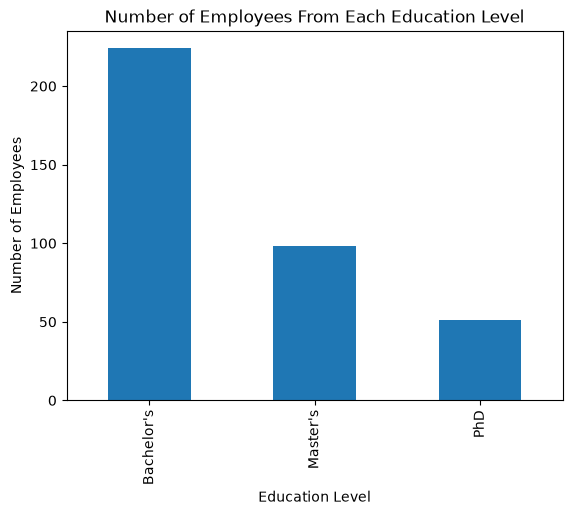

In [7]:
# bar chart of results - this part is done for you
df["Education Level"].value_counts().plot(kind="bar")
plt.title("Number of Employees From Each Education Level")
plt.ylabel("Number of Employees")
plt.show()

`e)` What are the possible values for `Salary`?  What does the distribution of `Salary` look like?

In [8]:
print(df["Salary"].value_counts())
print(df["Salary"].nunique())

df["Salary"].describe()

Salary
40000.0     31
50000.0     22
95000.0     22
180000.0    20
120000.0    20
90000.0     18
150000.0    18
45000.0     18
160000.0    17
60000.0     17
110000.0    17
170000.0    16
130000.0    14
100000.0    14
140000.0    14
35000.0     13
80000.0     12
55000.0     10
85000.0     10
70000.0      9
65000.0      9
105000.0     6
190000.0     4
75000.0      4
115000.0     3
250000.0     2
200000.0     2
135000.0     2
175000.0     2
125000.0     1
30000.0      1
220000.0     1
185000.0     1
145000.0     1
155000.0     1
350.0        1
Name: count, dtype: int64
36


count       373.000000
mean     100577.345845
std       48240.013482
min         350.000000
25%       55000.000000
50%       95000.000000
75%      140000.000000
max      250000.000000
Name: Salary, dtype: float64

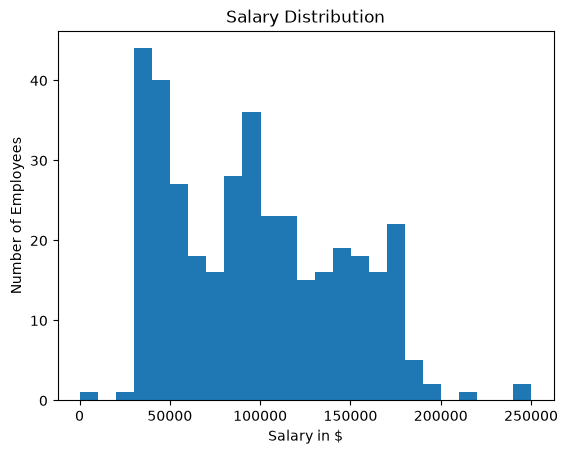

In [9]:
salary_hist_ax = df.plot.hist(column=["Salary"], bins=25, legend=False)
salary_hist_ax.set_xlabel("Salary in $")
salary_hist_ax.set_ylabel("Number of Employees")
salary_hist_ax.set_title("Salary Distribution")
plt.show()

<a id='regression'></a>
#### Part II - Regression

`1.` Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `Salary`.

`a)` Consider average salary by gender, is there evidence that salaries are higher for one gender over the other?

In [10]:
df.groupby("Gender")["Salary"].describe()

,count,mean,std,min,25%,50%,75%,max
Gender,,,,,,,,
Female,179.0,97011.173184,45916.141054,35000.0,50000.0,90000.0,140000.0,190000.0
Male,194.0,103867.783505,50182.461438,350.0,60000.0,97500.0,140000.0,250000.0


`b)` Consider average salary by education level, is there evidence that salaries are higher for increased education?

In [11]:
df.groupby("Education Level")["Salary"].describe()

,count,mean,std,min,25%,50%,75%,max
Education Level,,,,,,,,
Bachelor's,224.0,74756.026786,34777.272704,350.0,45000.0,65000.0,95000.0,250000.0
Master's,98.0,129795.918367,41659.631919,40000.0,95000.0,120000.0,170000.0,200000.0
PhD,51.0,157843.137255,23393.479903,110000.0,150000.0,155000.0,160000.0,250000.0


`c)` Consider average salary by years of experience, is there evidence that salaries are associated with increased years of experience?

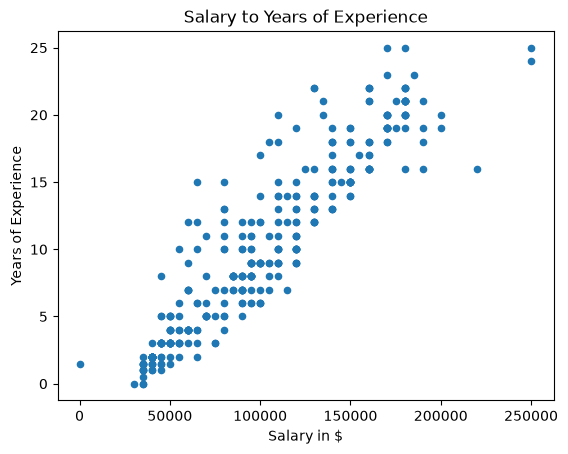

In [12]:
salary_to_exp_ax = df.plot.scatter(["Salary"], ["Years of Experience"])
salary_to_exp_ax.set_xlabel("Salary in $")
salary_to_exp_ax.set_ylabel("Years of Experience")
salary_to_exp_ax.set_title("Salary to Years of Experience")
plt.show()

`d)`  To make use of Job Title column lets create bool flag based on word existiance


List of words:

* Director
* Junior
* Senior
* Manager
* Analyst
* Engineer

**This question is completed for you**

In [13]:
flag_words = ["director", "junior", "senior", "manager", "analyst", "engineer"]
df["Job Title"] = df["Job Title"].str.lower()
job_titles = []

for word in flag_words:
    job_title = "is_" + word
    df[job_title] = df["Job Title"].str.contains(word)
    job_titles.append(job_title)

df = df.drop("Job Title", axis=1)

In [14]:
# search for rows that did not match any of the job title flag words
no_job_title_flag = ~df[job_titles].any(axis=1)
print(
    f"{no_job_title_flag.sum()} of {len(df)} rows match none of the job title flag words"
)

46 of 373 rows match none of the job title flag words


`e)` Create a flag for gender where 1 is if a person is male and 0 if the person is not.

In [15]:
df = df.join(pd.get_dummies(df["Gender"], dtype=int))

`f)` Use statsmodels to fit a linear model to predict salary using each of the features from `a-e`.  These include:
* Gender
* Job TItle
* Years of Experience
* Education

In [16]:
# predictor variables and baselines
df = df.join(pd.get_dummies(df["Education Level"], dtype=int))
df["intercept"] = 1
df.head()

,Age,Gender,Education Level,Years of Experience,Salary,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer,Female,Male,Bachelor's,Master's,PhD,intercept
0,32.0,Male,Bachelor's,5.0,90000.0,False,False,False,False,False,True,0,1,1,0,0,1
1,28.0,Female,Master's,3.0,65000.0,False,False,False,False,True,False,1,0,0,1,0,1
2,45.0,Male,PhD,15.0,150000.0,False,False,True,True,False,False,0,1,0,0,1,1
3,36.0,Female,Bachelor's,7.0,60000.0,False,False,False,False,False,False,1,0,1,0,0,1
4,52.0,Male,Master's,20.0,200000.0,True,False,False,False,False,False,0,1,0,1,0,1


In [17]:
education_levels = list(df["Education Level"].unique())

# verify baselines will represent a significant sample
# job_title will not have a baseline since the categorization was not exhaustive
print(df.groupby(["Gender"])["Education Level"].value_counts())

gender_baseline = "Female"
education_level_baseline = "Bachelor's"
education_levels.remove(education_level_baseline)
print(f"baseline columns: '{gender_baseline}', '{education_level_baseline}'")

predictors = (
    ["intercept", "Male", "Years of Experience"] + education_levels + job_titles
)
print(f"predictors: {predictors}")

Gender  Education Level
Female  Bachelor's         103
        Master's            50
        PhD                 26
Male    Bachelor's         121
        Master's            48
        PhD                 25
Name: count, dtype: int64
baseline columns: 'Female', 'Bachelor's'
predictors: ['intercept', 'Male', 'Years of Experience', "Master's", 'PhD', 'is_director', 'is_junior', 'is_senior', 'is_manager', 'is_analyst', 'is_engineer']


In [18]:
salary_model = sm.OLS(df["Salary"], df[predictors])
salary_model_results = salary_model.fit()
salary_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     391.7
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          2.41e-187
Time:                        21:06:55   Log-Likelihood:                -4090.6
No. Observations:                 373   AIC:                             8203.
Df Residuals:                     362   BIC:                             8246.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
intercept            3.212e+04   2485.604     12.921      0.000    2.72e+04     3.7e+04
Male                 7484.7304   1509.904      4.957      0.000    4515.446    1.05e+04
Years of Experience  4937.4278    197.548     24.994      0.000    4548.941    5325.914
Master's             1.345e+04   2053.896      6.547      0.000    9408.638    1.75e+04
PhD                  2.327e+04   2801.927      8.304      0.000    1.78e+04    2.88e+04
is_director          2.539e+04   3535.194      7.181      0.000    1.84e+04    3.23e+04
is_junior           -4492.5634   2458.516     -1.827      0.068   -9327.330     342.203
is_senior            1.307e+04   1976.833      6.610      0.000    9178.417     1.7e+04
is_manager           4434.5081   1960.352      2.262      0.024     579.400    8289.617
is_analyst           -176.3409   2103.878     -0.084      0.933   -4313.698    3961.016
is_engineer          2362.9515   3561.972      0.663      0.508   -4641.805    9367.708
==============================================================================
Omnibus:                      130.784   Durbin-Watson:                   1.815
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1091.992
Skew:                           1.230   Prob(JB):                    7.53e-238
Kurtosis:                      11.013   Cond. No.                         63.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<a id='interpretation'></a>
### Part III - Interpret Results

`1.` Consider you are tasked with finding which features in your linear model are significantly related to salary.  Were there any features that were not significantly related to salary in your first model?  If not, remove those features and fit a new model.  Only keep the features that were significant from the original model.

In [19]:
# explain your answer and fit a new model with the reduced set of features here
print("omitting insignificant predictor variables (p-value > 0.05):")

for p, v in salary_model_results.pvalues.items():
    if p != "intercept" and v > 0.05:
        print(f"  {p:<15}{v:.4f}")
        predictors.remove(p)

salary_model = sm.OLS(df["Salary"], df[predictors])
salary_model_results = salary_model.fit()
salary_model_results.summary2()

omitting insignificant predictor variables (p-value > 0.05):
  is_junior      0.0685
  is_analyst     0.9332
  is_engineer    0.5075


<class 'statsmodels.iolib.summary2.Summary'>
"""
                       Results: Ordinary least squares
=============================================================================
Model:                  OLS                 Adj. R-squared:        0.913     
Dependent Variable:     Salary              AIC:                   8201.2236 
Date:                   2026-10-14 21:06    BIC:                   8232.5962 
No. Observations:       373                 Log-Likelihood:        -4092.6   
Df Model:               7                   F-statistic:           557.4     
Df Residuals:           365                 Prob (F-statistic):    1.46e-190 
R-squared:              0.914               Scale:                 2.0288e+08
-----------------------------------------------------------------------------
                      Coef.     Std.Err.    t    P>|t|    [0.025     0.975]  
-----------------------------------------------------------------------------
intercept           28760.7838 1677.4107 17.1459 0.0000 25462.1814 32059.3861
Male                 7629.6521 1481.8337  5.1488 0.0000  4715.6489 10543.6554
Years of Experience  5104.4388  177.2257 28.8019 0.0000  4755.9271  5452.9504
Master's            14037.3184 2032.0782  6.9079 0.0000 10041.2678 18033.3689
PhD                 23080.8487 2760.7396  8.3604 0.0000 17651.8968 28509.8006
is_director         24980.8432 3503.0277  7.1312 0.0000 18092.1931 31869.4933
is_senior           14446.4757 1820.4275  7.9358 0.0000 10866.6331 18026.3183
is_manager           4284.6595 1822.5824  2.3509 0.0193   700.5792  7868.7397
-----------------------------------------------------------------------------
Omnibus:                 126.635          Durbin-Watson:             1.790   
Prob(Omnibus):           0.000            Jarque-Bera (JB):          1010.895
Skew:                    1.196            Prob(JB):                  0.000   
Kurtosis:                10.702           Condition No.:             61      
=============================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is
correctly specified.
"""

`a)` With each additional year of experience, what is the expected change in salary?  What is the 95% confidence interval of the change?

**Your Answer Here**

`b)` What is the expected difference in salary between someone with a senior title and someone with none of the other title indications?

**Your Answer Here**

`c)` What is the expected difference in salary between someone with a PhD and an individual with no PhD nor master's degree?  What is the 95% confidence interval of the change?

**Your Answer Here**

`d)` If a male employee has 5 years of experience as a senior engineer with a bachelor's degree, what is the expected salary of the employee?

**Your Answer Here**

`e)` Imagine that the employee in question `d)` actually has a salary of $110,000, what would the residual be for this employee?

**Your Answer Here**

`f)` How well do you think your model fits?  What metrics or plots would you consider to understand if this model does a good job of predicting salary?

In [20]:
### Your work here

**Your Answer Here**

<a id='finalcheck'></a>
## Final Check!

Congratulations!  You have reached the end of the salary prediction project!  You should be very proud of all you have accomplished!

> **Tip**: Once you are satisfied with your work here, check over your notebook to make sure that it satisfies all the specifications mentioned in the rubric. You should also probably remove all of the "Hints" and "Tips" like this one so that the presentation is as polished as possible.


<a id='submission'></a>
## Submission

Please follow the directions in the classroom to submit this notebook, as well as your completed slides.